# Chapitre 3 - Cours 2 : sélection de variables, ridge et lasso

Ce notebook couvre les sections 3.3 et 3.4 du livre. Les moindres carrés ont deux défauts :

- **précision de prédiction** : ils sont sans biais mais souvent de grande variance ; en
  annulant ou en rétrécissant certains coefficients, on accepte un peu de biais pour
  réduire la variance (cf. cours 1, §5) ;
- **interprétation** : avec beaucoup de prédicteurs, on préfère un petit sous-ensemble aux
  effets les plus forts.

Deux familles de remèdes sont étudiées ici, toujours sur les données de la prostate :

1. la **sélection de sous-ensembles** : meilleur sous-ensemble, pas à pas ascendant et
   descendant, régression « stagewise » ;
2. les méthodes de **rétrécissement** (*shrinkage*) : régression **ridge** et **lasso**.

Nous reproduisons les figures 3.5, 3.8, 3.10, 3.11, 3.12 et les panneaux correspondants de
la figure 3.7 (courbes de validation croisée).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

import pandas as pd
from sklearn.linear_model import Lasso, Ridge
from esl import ch03_regression as cr

pd.set_option("display.precision", 3)


def label_ends(ax, x, values, labels, gap=0.035):
    """Écrit les noms des variables au bout des profils en évitant les chevauchements."""
    order = np.argsort(values)
    pos = np.array(values, float)[order]
    for i in range(1, len(pos)):
        pos[i] = max(pos[i], pos[i - 1] + gap)
    for k, j in enumerate(order):
        ax.text(x, pos[k], labels[j], color=COLORS[j], fontsize=8, va="center")

Données de la prostate standardisées (comme au cours 1) : 67 observations
d'apprentissage, 30 de test, 8 prédicteurs.

In [2]:
Xtr, ytr, Xte, yte, names = cr.load_prostate_standardized()
N, p = Xtr.shape
fit_ls = cr.ols_fit(Xtr, ytr)


def test_error(b0, beta):
    """Erreur quadratique moyenne sur l'échantillon de test."""
    return np.mean((yte - b0 - Xte @ beta) ** 2)


print("moindres carrés : erreur de test = %.3f" % test_error(fit_ls["coef"][0], fit_ls["coef"][1:]))

moindres carrés : erreur de test = 0.521


## 1. Sélection du meilleur sous-ensemble

Pour chaque taille $k \in \{0, 1, \dots, p\}$, la **sélection du meilleur sous-ensemble**
(*best subset*) cherche le sous-ensemble de $k$ variables dont la régression par moindres
carrés a le plus petit RSS. Avec $p = 8$, il n'y a que $2^8 = 256$ sous-ensembles : on
peut tous les essayer. (Pour $p$ jusqu'à 30 ou 40, l'algorithme *leaps and bounds* évite
l'énumération complète ; au-delà, c'est impraticable.)

In [3]:
all_rss = cr.all_subsets_rss(Xtr, ytr)
subsets, best_rss = cr.best_subset(Xtr, ytr)
print("nombre de sous-ensembles :", len(all_rss))
pd.DataFrame({"meilleur sous-ensemble": [", ".join(names[j] for j in S) or "(constante)" for S in subsets],
              "RSS": best_rss}, index=pd.Index(range(p + 1), name="k"))

nombre de sous-ensembles : 256


,meilleur sous-ensemble,RSS
k,,
0,(constante),96.281
1,lcavol,44.529
2,"lcavol, lweight",37.092
3,"lcavol, lweight, svi",34.908
4,"lcavol, lweight, lbph, svi",32.815
5,"lcavol, lweight, lbph, svi, pgg45",32.069
6,"lcavol, lweight, lbph, svi, lcp, pgg45",30.540
7,"lcavol, lweight, age, lbph, svi, lcp, pgg45",29.437
8,"lcavol, lweight, age, lbph, svi, lcp, gleason,...",29.426


La figure 3.5 du livre montre le RSS de **tous** les sous-ensembles, rangés par taille ;
la frontière inférieure (en orange) est formée des meilleurs sous-ensembles.

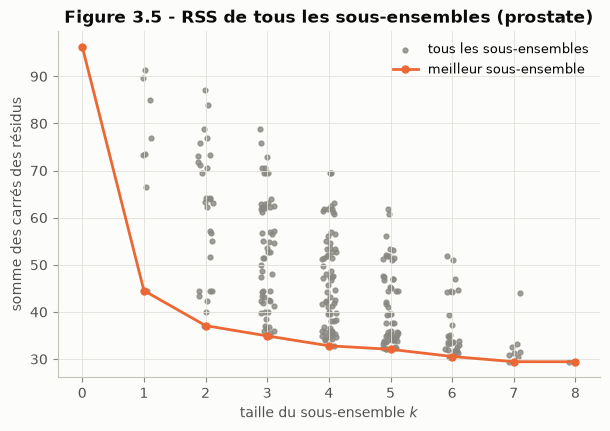

In [4]:
rng = np.random.RandomState(0)
ks = np.array([len(S) for S, _ in all_rss])
rs = np.array([r for _, r in all_rss])
fig, ax = plt.subplots()
ax.scatter(ks + rng.uniform(-0.12, 0.12, len(ks)), rs, s=12, color=GRAY, alpha=0.8,
           label="tous les sous-ensembles")
ax.plot(range(p + 1), best_rss, "o-", color=ORANGE, label="meilleur sous-ensemble")
ax.set_title("Figure 3.5 - RSS de tous les sous-ensembles (prostate)")
ax.set_xlabel("taille du sous-ensemble $k$"); ax.set_ylabel("somme des carrés des résidus")
ax.legend()
plt.show()

Ici les meilleurs sous-ensembles sont **emboîtés** (chacun contient le précédent), mais ce
n'est pas garanti en général. Surtout, la courbe des meilleurs RSS est **décroissante** :
plus de variables, meilleur ajustement sur l'apprentissage. Elle ne peut donc pas servir à
choisir $k$ ; il faut un critère qui estime l'**erreur de prédiction** sur de nouvelles
données.

## 2. Choisir la complexité : la validation croisée

La plupart des méthodes de ce chapitre produisent une **famille de modèles** indexée par
un paramètre de complexité ($k$, $\lambda$, $s$, $M$…). Pour choisir ce paramètre, on
utilise ici la **validation croisée à $K = 10$ plis** (détaillée au chapitre 7) :

1. on partage aléatoirement les $N$ observations d'apprentissage en $K$ parts égales ;
2. pour chaque part $\kappa$, on ajuste toute la famille sur les $K-1$ autres parts et
   l'on calcule l'erreur quadratique moyenne $e_\kappa$ sur la part $\kappa$ ;
3. l'erreur estimée est $\mathrm{CV} = \frac{1}{K}\sum_{\kappa} e_\kappa$, avec l'erreur
   standard $\mathrm{se} = \mathrm{sd}(e_1, \dots, e_K)/\sqrt{K}$.

**Règle « un écart-type ».** Les courbes de validation croisée sont souvent très plates
près de leur minimum, et elles sont estimées avec erreur. On retient donc le modèle **le
plus simple** dont l'erreur CV est inférieure à $\mathrm{CV}_{\min} + \mathrm{se}_{\min}$
(minimum plus son erreur standard).

> **Remarque.** Le résultat dépend du découpage aléatoire en plis. Nous fixons un découpage
> (graine 12, qui donne des choix proches de ceux du livre) et l'utilisons pour **toutes**
> les méthodes ; la variabilité due au découpage est étudiée dans le cours 3.

In [5]:
folds = cr.kfold_indices(N, K=10, rng=np.random.RandomState(12))
print("tailles des plis :", [len(f) for f in folds])


def plot_cv(ax, grid, mean, se, title, xlabel):
    """Courbe de validation croisée avec barres d'erreur et choix « un écart-type »."""
    i_best = cr.one_se_rule(mean, se)
    ax.errorbar(grid, mean, yerr=se, fmt="o-", color=ORANGE, ecolor=BLUE,
                capsize=3, markersize=4, linewidth=1.5)
    ax.axhline(mean.min() + se[np.argmin(mean)], color=GRAY, linestyle=":", linewidth=1)
    ax.axvline(grid[i_best], color=COLORS[6], linestyle="--", linewidth=1)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("erreur de validation croisée")
    ax.set_ylim(0.3, 1.8)
    return i_best

tailles des plis : [7, 7, 7, 7, 7, 7, 7, 6, 6, 6]


Panneau « All Subsets » de la figure 3.7 : erreur CV du meilleur sous-ensemble en
fonction de sa taille.

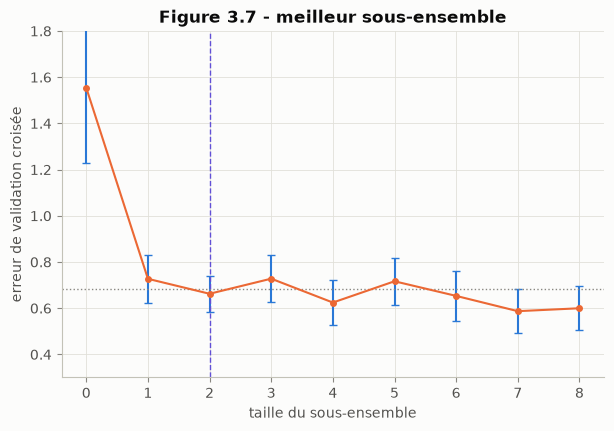

taille retenue par la règle un écart-type : 2 -> ['lcavol', 'lweight']


In [6]:
cv_bs, se_bs = cr.cv_error(cr.best_subset_path, Xtr, ytr, folds)
fig, ax = plt.subplots()
k_bs = plot_cv(ax, np.arange(p + 1), cv_bs, se_bs, "Figure 3.7 - meilleur sous-ensemble",
               "taille du sous-ensemble")
plt.show()
print("taille retenue par la règle un écart-type :", k_bs, "->", [names[j] for j in subsets[k_bs]])

Comme dans le livre, la règle retient les **deux** prédicteurs `lcavol` et `lweight`.
Le pointillé horizontal marque le seuil $\mathrm{CV}_{\min} + \mathrm{se}_{\min}$, le tireté
vertical le modèle choisi.

In [7]:
b0_bs, B_bs = cr.best_subset_path(Xtr, ytr)
print("coefficients :", dict(zip(["intercept"] + names, np.r_[b0_bs[k_bs], B_bs[k_bs]].round(3))))
print("erreur de test : %.3f" % test_error(b0_bs[k_bs], B_bs[k_bs]))

coefficients : {'intercept': np.float64(2.477), 'lcavol': np.float64(0.74), 'lweight': np.float64(0.316), 'age': np.float64(0.0), 'lbph': np.float64(0.0), 'svi': np.float64(0.0), 'lcp': np.float64(0.0), 'gleason': np.float64(0.0), 'pgg45': np.float64(0.0)}
erreur de test : 0.492


## 3. Sélection pas à pas

### 3.1 Pas à pas ascendante (*forward stepwise*)

Au lieu d'explorer tous les sous-ensembles, on construit un **chemin** : on part de la
constante seule, puis on ajoute à chaque étape la variable qui **diminue le plus le RSS**.
C'est un algorithme **glouton**, qui produit une suite de modèles emboîtés.

Avantages : coût faible (possible même si $p \gg N$), et recherche plus contrainte, donc
**moins de variance** que le meilleur sous-ensemble (au prix d'un peu de biais).

**Mise à jour efficace (exercice 3.9).** Soit $\mathbf{Q}$ une base orthonormée des
variables déjà retenues (constante incluse) et $\mathbf{r}$ le résidu courant. Pour une
candidate $\mathbf{x}_j$, notons $\mathbf{e}_j = \mathbf{x}_j - \mathbf{Q}\mathbf{Q}^T\mathbf{x}_j$
sa partie orthogonale aux variables retenues. L'ajouter revient à projeter $\mathbf{r}$ sur
$\mathbf{e}_j$, ce qui diminue le RSS de

$$
\Delta_j = \frac{\langle \mathbf{e}_j, \mathbf{r}\rangle^2}{\lVert\mathbf{e}_j\rVert^2}.
$$

On choisit le $j$ qui maximise $\Delta_j$, puis on ajoute $\mathbf{e}_j/\lVert\mathbf{e}_j\rVert$
à $\mathbf{Q}$ (une étape de Gram–Schmidt).

In [8]:
order_fw, rss_fw = cr.forward_stepwise(Xtr, ytr)
print("ordre d'entrée :", [names[j] for j in order_fw])
print("RSS            :", rss_fw.round(2))

ordre d'entrée : ['lcavol', 'lweight', 'svi', 'lbph', 'pgg45', 'lcp', 'age', 'gleason']
RSS            : [96.28 44.53 37.09 34.91 32.81 32.07 30.54 29.44 29.43]


### 3.2 Pas à pas descendante (*backward stepwise*)

On part du modèle complet et l'on retire à chaque étape la variable dont le retrait
**augmente le moins le RSS**. D'après l'exercice 3.1, cette hausse vaut
$z_j^2\,\hat\sigma^2$ : on retire la variable de plus petit $|z_j|$ (exercice 3.10). Cette
méthode exige $N > p$.

In [9]:
removed_bw, rss_bw = cr.backward_stepwise(Xtr, ytr)
print("ordre de retrait :", [names[j] for j in removed_bw])
print("ordre d'entrée équivalent :", [names[j] for j in removed_bw[::-1]])

ordre de retrait : ['gleason', 'age', 'lcp', 'pgg45', 'lbph', 'svi', 'lweight', 'lcavol']
ordre d'entrée équivalent : ['lcavol', 'lweight', 'svi', 'lbph', 'pgg45', 'lcp', 'age', 'gleason']


Sur la prostate, meilleur sous-ensemble, pas à pas ascendante et descendante donnent
**exactement la même suite** de modèles (comme le signale le livre) :

In [10]:
same = all(set(subsets[k]) == set(order_fw[:k]) == set(removed_bw[::-1][:k]) for k in range(p + 1))
print("mêmes sous-ensembles pour chaque k ?", same)

mêmes sous-ensembles pour chaque k ? True


> **Attention.** Après une recherche de modèle, les erreurs standard affichées par une
> régression (comme au tableau 3.2) ne sont **plus valides** : elles ignorent que les
> variables ont été choisies au vu des données. Le bootstrap (chapitre 8) peut aider.

### 3.3 Régression « stagewise » ascendante (*forward stagewise*)

Encore plus contrainte : on part de $\beta = 0$ (constante $\bar y$, prédicteurs centrés).
À chaque étape :

1. on cherche la variable $\mathbf{x}_j$ la plus corrélée au résidu courant $\mathbf{r}$ ;
2. on ajoute à $\beta_j$ le coefficient de la régression **simple** de $\mathbf{r}$ sur
   $\mathbf{x}_j$, soit $\langle\mathbf{x}_j, \mathbf{r}\rangle/\lVert\mathbf{x}_j\rVert^2$ ;
3. on met à jour $\mathbf{r}$.

Contrairement au pas à pas, les **autres coefficients ne sont pas réajustés** : il faut
souvent beaucoup plus de $p$ étapes pour atteindre les moindres carrés.

In [11]:
path_fs = cr.forward_stagewise(Xtr, ytr, n_steps=400)
print("nombre d'étapes effectuées :", len(path_fs) - 1)
print("écart final aux moindres carrés : %.2e" % np.abs(path_fs[-1] - fit_ls["coef"][1:]).max())

nombre d'étapes effectuées : 305
écart final aux moindres carrés : 4.62e-11


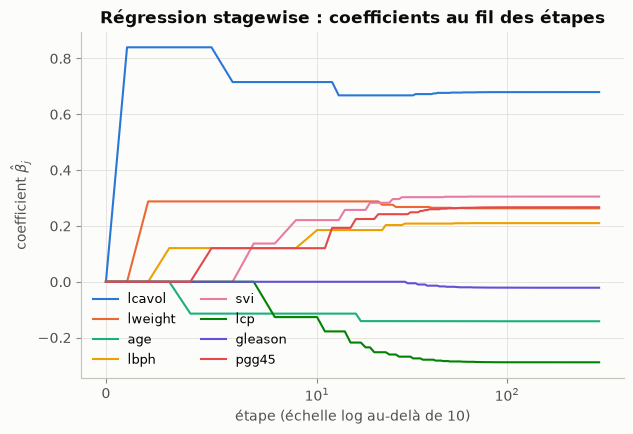

In [12]:
fig, ax = plt.subplots()
for j in range(p):
    ax.plot(path_fs[:, j], color=COLORS[j], label=names[j], linewidth=1.5)
ax.set_xscale("symlog", linthresh=10)
ax.set_title("Régression stagewise : coefficients au fil des étapes")
ax.set_xlabel("étape (échelle log au-delà de 10)"); ax.set_ylabel(r"coefficient $\hat\beta_j$")
ax.legend(ncol=2)
plt.show()

Les premières étapes font entrer `lcavol`, `lweight`, `svi`… puis l'algorithme met des
centaines d'étapes à converger vers les moindres carrés : les variables corrélées se
« disputent » le résidu. Cette lenteur, longtemps jugée inefficace, s'avère utile en grande
dimension (§3.8 du livre).

Une variante encore plus lente, **FS$_\varepsilon$** (algorithme 3.4 du livre), ajoute
seulement $\varepsilon\cdot\mathrm{signe}\langle\mathbf{x}_j, \mathbf{r}\rangle$ au
coefficient choisi. Avec $\varepsilon$ petit, son chemin ressemble à celui du lasso
(comparer à la figure 3.10 plus bas ; c'est la figure 3.19 du livre).

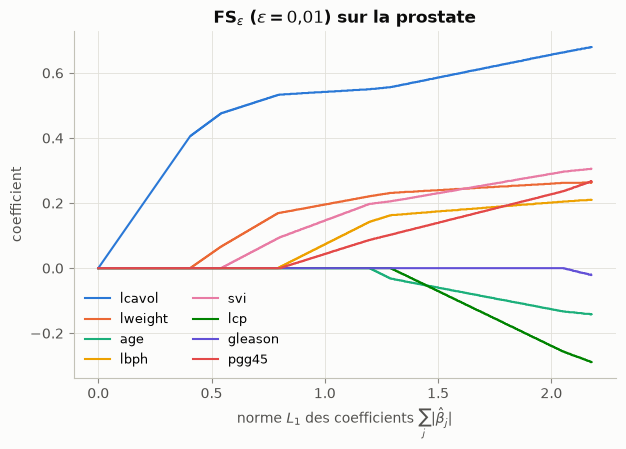

In [13]:
Xn = (Xtr - Xtr.mean(0)) / np.linalg.norm(Xtr - Xtr.mean(0), axis=0)   # colonnes de norme 1
path_eps = cr.forward_stagewise(Xn, ytr, eps=0.01, n_steps=2500)
scale = np.linalg.norm(Xtr - Xtr.mean(0), axis=0)
path_eps_orig = path_eps / scale                     # retour à l'échelle des X standardisés
fig, ax = plt.subplots()
l1 = np.abs(path_eps_orig).sum(1)
for j in range(p):
    ax.plot(l1, path_eps_orig[:, j], color=COLORS[j], label=names[j], linewidth=1.5)
ax.set_title(r"FS$_\varepsilon$ ($\varepsilon = 0{,}01$) sur la prostate")
ax.set_xlabel(r"norme $L_1$ des coefficients $\sum_j|\hat\beta_j|$"); ax.set_ylabel("coefficient")
ax.legend(ncol=2)
plt.show()

### 3.4 Comparaison sur simulation (figure 3.6, version réduite)

Le livre compare ces méthodes sur un problème simulé : $N = 300$, $p = 31$ variables
gaussiennes de corrélation deux à deux $0{,}85$, dont 10 ont un coefficient tiré selon
$\mathcal{N}(0, 0{,}4)$ (les autres nuls), bruit $\mathcal{N}(0, 6{,}25)$. Il trace
$\mathbb{E}\lVert\hat\beta(k) - \beta\rVert^2$ en fonction de la taille $k$.

Avec $p = 31$, le meilleur sous-ensemble demanderait $2^{31} \approx 2\cdot10^9$
régressions : nous l'omettons (le livre utilise *leaps and bounds*) et faisons 20
simulations au lieu de 50, pour garder un temps de calcul raisonnable.

In [14]:
def simulate_fig36(rng, N=300, p=31, rho=0.85):
    L = np.linalg.cholesky(rho * np.ones((p, p)) + (1 - rho) * np.eye(p))
    X = rng.randn(N, p) @ L.T
    beta = np.zeros(p)
    idx = rng.choice(p, 10, replace=False)
    beta[idx] = rng.randn(10) * np.sqrt(0.4)
    y = X @ beta + rng.randn(N) * 2.5
    return X, y, beta


def subset_coefs(X, y, order):
    """Coefficients (sans constante) des modèles emboîtés suivant ``order``."""
    out = [np.zeros(X.shape[1])]
    for k in range(1, len(order) + 1):
        out.append(cr.subset_fit(X, y, order[:k])[1])
    return np.array(out)


rng = np.random.RandomState(0)
n_sim, P = 20, 31
err = {"pas à pas ascendante": np.zeros(P + 1), "pas à pas descendante": np.zeros(P + 1),
       "stagewise": np.zeros(P + 1)}
for _ in range(n_sim):
    X, y, beta = simulate_fig36(rng)
    order, _ = cr.forward_stepwise(X, y)
    err["pas à pas ascendante"] += np.sum((subset_coefs(X, y, order) - beta) ** 2, axis=1)
    removed, _ = cr.backward_stepwise(X, y)
    err["pas à pas descendante"] += np.sum((subset_coefs(X, y, removed[::-1]) - beta) ** 2, axis=1)
    path = cr.forward_stagewise(X, y, n_steps=3000)
    nz = np.sum(path != 0, axis=1)
    e_fs = np.full(P + 1, np.nan)
    for k in range(P + 1):
        steps = np.where(nz == k)[0]
        if len(steps):
            e_fs[k] = np.sum((path[steps[-1]] - beta) ** 2)   # dernière étape à k variables
    err["stagewise"] += e_fs
err = {k: v / n_sim for k, v in err.items()}

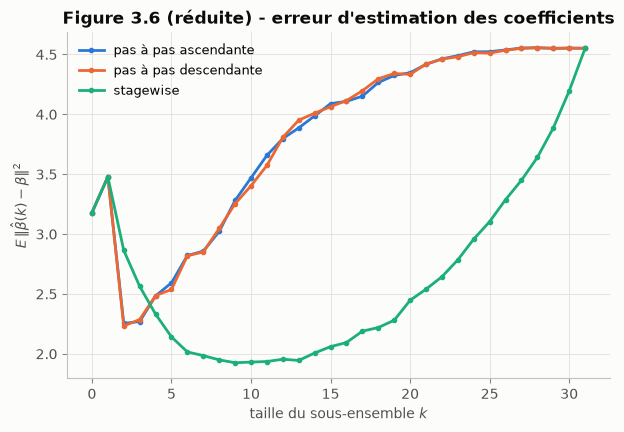

In [15]:
fig, ax = plt.subplots()
for (lab, e), col in zip(err.items(), COLORS):
    ax.plot(range(P + 1), e, "o-", color=col, markersize=3, label=lab)
ax.set_title("Figure 3.6 (réduite) - erreur d'estimation des coefficients")
ax.set_xlabel("taille du sous-ensemble $k$"); ax.set_ylabel(r"$E\,\|\hat\beta(k) - \beta\|^2$")
ax.legend()
plt.show()

Les deux méthodes pas à pas se comportent de façon **très semblable**, comme dans le livre.
Avec ce rapport signal/bruit faible et des variables très corrélées, leur erreur est
minimale pour de petits modèles puis remonte vers celle des moindres carrés ($k = 31$) :
ajouter des variables coûte plus en variance qu'il ne rapporte en biais. La régression
stagewise, plus lente, atteint son minimum plus tard ; à $k$ fixé ses coefficients sont
encore **rétrécis** (ils n'ont pas fini de croître), ce qui lui donne ici une erreur plus
faible. (L'échelle verticale diffère de celle du livre, dont tous les paramètres de
simulation ne sont pas précisés ; ce sont les comportements relatifs qui comptent.)

## 4. Régression ridge

La sélection est un processus **discret** (une variable est gardée ou jetée), ce qui la
rend instable : de petites perturbations des données changent le sous-ensemble choisi.
Les méthodes de **rétrécissement** sont plus continues.

La **régression ridge** pénalise la taille des coefficients (éq. (3.41)) :

$$
\hat\beta^{\mathrm{ridge}} = \underset{\beta}{\mathrm{argmin}}
\Bigl\{\sum_{i=1}^N\Bigl(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\Bigr)^2 + \lambda\sum_{j=1}^p\beta_j^2\Bigr\},
$$

où $\lambda \ge 0$ règle la force du rétrécissement : $\lambda = 0$ donne les moindres
carrés, $\lambda \to \infty$ écrase tous les $\beta_j$ vers 0.

**Forme contrainte.** De façon équivalente (éq. (3.42)), on minimise le RSS sous la
contrainte $\sum_j \beta_j^2 \le t$ ; il y a une correspondance bijective entre $\lambda$
et $t$ (multiplicateur de Lagrange).

> **Remarques pratiques.**
> - La solution **dépend de l'échelle** des entrées : on les standardise d'abord.
> - L'ordonnée à l'origine $\beta_0$ n'est **pas pénalisée** (sinon ajouter une constante
>   à $y$ ne décalerait pas simplement les prédictions).
> - En centrant les entrées ($x_{ij} \leftarrow x_{ij} - \bar x_j$), on obtient
>   $\hat\beta_0 = \bar y$ et les autres coefficients se calculent sans constante
>   (exercice 3.5). On suppose désormais $\mathbf{X}$ centrée, à $p$ colonnes.

### 4.1 Solution explicite

Le critère s'écrit matriciellement (éq. (3.43))

$$
\mathrm{RSS}(\lambda) = (\mathbf{y} - \mathbf{X}\beta)^T(\mathbf{y} - \mathbf{X}\beta) + \lambda\beta^T\beta .
$$

Son gradient est $-2\mathbf{X}^T(\mathbf{y} - \mathbf{X}\beta) + 2\lambda\beta$. L'annuler
donne $(\mathbf{X}^T\mathbf{X} + \lambda\mathbf{I})\beta = \mathbf{X}^T\mathbf{y}$, d'où
(éq. (3.44))

$$
\hat\beta^{\mathrm{ridge}} = (\mathbf{X}^T\mathbf{X} + \lambda\mathbf{I})^{-1}\mathbf{X}^T\mathbf{y}.
$$

Pour $\lambda > 0$, $\mathbf{X}^T\mathbf{X} + \lambda\mathbf{I}$ est **toujours inversible**
(ses valeurs propres sont $\ge \lambda > 0$), même si $\mathbf{X}$ n'est pas de rang plein :
c'était la motivation historique de la méthode.

**Cas orthonormé.** Si $\mathbf{X}^T\mathbf{X} = \mathbf{I}$, alors
$\hat\beta^{\mathrm{ridge}} = \hat\beta/(1 + \lambda)$ : tous les coefficients sont
rétrécis du **même facteur**.

### 4.2 Lecture par la décomposition en valeurs singulières

**Rappel (SVD).** Toute matrice $\mathbf{X}$ ($N\times p$, $N \ge p$) s'écrit (éq. (3.45))
$\mathbf{X} = \mathbf{U}\mathbf{D}\mathbf{V}^T$, avec $\mathbf{U}$ ($N\times p$) et
$\mathbf{V}$ ($p\times p$) à colonnes orthonormées et
$\mathbf{D} = \mathrm{diag}(d_1 \ge \dots \ge d_p \ge 0)$ (valeurs singulières).

Alors $\mathbf{X}^T\mathbf{X} + \lambda\mathbf{I} = \mathbf{V}(\mathbf{D}^2 + \lambda\mathbf{I})\mathbf{V}^T$
et l'on obtient (éq. (3.46)–(3.47)) :

$$
\begin{aligned}
\mathbf{X}\hat\beta^{\mathrm{ls}} &= \mathbf{U}\mathbf{U}^T\mathbf{y}
  = \sum_{j=1}^p \mathbf{u}_j\,\mathbf{u}_j^T\mathbf{y}, \\
\mathbf{X}\hat\beta^{\mathrm{ridge}} &= \mathbf{U}\mathbf{D}(\mathbf{D}^2 + \lambda\mathbf{I})^{-1}\mathbf{D}\mathbf{U}^T\mathbf{y}
  = \sum_{j=1}^p \mathbf{u}_j\,\frac{d_j^2}{d_j^2 + \lambda}\,\mathbf{u}_j^T\mathbf{y}.
\end{aligned}
$$

> **Intuition.** Ridge exprime $\mathbf{y}$ dans la base orthonormée $\mathbf{u}_j$, puis
> rétrécit chaque coordonnée du facteur $d_j^2/(d_j^2 + \lambda) \le 1$ : les directions de
> **petite** valeur singulière sont les plus rétrécies.

**Composantes principales.** La matrice de covariance empirique est
$\mathbf{S} = \mathbf{X}^T\mathbf{X}/N = \mathbf{V}\mathbf{D}^2\mathbf{V}^T/N$ (éq. (3.48)) :
les $\mathbf{v}_j$ sont les **directions principales** de $\mathbf{X}$. La première
composante $\mathbf{z}_1 = \mathbf{X}\mathbf{v}_1 = d_1\mathbf{u}_1$ est la combinaison
linéaire normée de plus grande variance empirique, $\mathrm{Var}(\mathbf{z}_1) = d_1^2/N$
(éq. (3.49)). Ridge rétrécit donc surtout les directions de **faible variance** des entrées.
Illustration en dimension 2 (figure 3.9 du livre) :

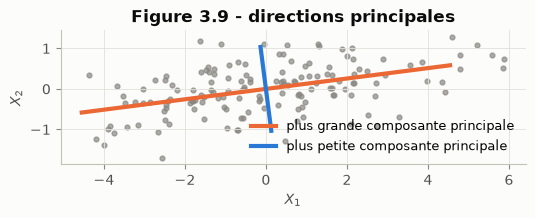

In [16]:
rng = np.random.RandomState(0)
pts = rng.randn(150, 2) @ np.array([[2.0, 0.0], [1.2, 0.6]])
pts -= pts.mean(0)
_, dpc, Vpc = np.linalg.svd(pts, full_matrices=False)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(pts[:, 0], pts[:, 1], s=12, color=GRAY, alpha=0.7)
for k, (lab, col) in enumerate([("plus grande composante principale", ORANGE),
                                ("plus petite composante principale", BLUE)]):
    v = Vpc[k] * dpc[k] / np.sqrt(len(pts)) * 2
    ax.plot([-v[0], v[0]], [-v[1], v[1]], color=col, linewidth=3, label=lab)
ax.set_aspect("equal")
ax.set_title("Figure 3.9 - directions principales")
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$")
ax.legend(loc="lower right")
plt.show()

### 4.3 Degrés de liberté effectifs

Pour les moindres carrés, le nombre de paramètres est $\mathrm{tr}(\mathbf{H}) = p$. Par
analogie, on définit les **degrés de liberté effectifs** de ridge (éq. (3.50)) :

$$
\mathrm{df}(\lambda) = \mathrm{tr}\bigl[\mathbf{X}(\mathbf{X}^T\mathbf{X} + \lambda\mathbf{I})^{-1}\mathbf{X}^T\bigr]
  = \sum_{j=1}^p \frac{d_j^2}{d_j^2 + \lambda},
$$

qui décroît de $p$ (pour $\lambda = 0$) à $0$ (pour $\lambda \to \infty$). C'est une échelle
plus parlante que $\lambda$ pour tracer les chemins.

In [17]:
Xc = Xtr - Xtr.mean(0)
d = np.linalg.svd(Xc, compute_uv=False)
print("valeurs singulières d_j :", d.round(2))
for lam in (0, 10, 50, 200):
    Hl = Xc @ np.linalg.solve(Xc.T @ Xc + lam * np.eye(p), Xc.T)
    print("lambda = %4d : df = %.3f, trace directe = %.3f" % (lam, cr.ridge_df(d, lam), np.trace(Hl)))

valeurs singulières d_j : [15.37 10.86  8.45  6.45  5.82  5.14  4.32  3.45]
lambda =    0 : df = 8.000, trace directe = 8.000
lambda =   10 : df = 6.257, trace directe = 6.257
lambda =   50 : df = 3.784, trace directe = 3.784
lambda =  200 : df = 1.751, trace directe = 1.751


Vérifions notre implémentation (par la SVD) contre `sklearn.linear_model.Ridge`, qui
minimise le même critère (son paramètre `alpha` est notre $\lambda$) :

In [18]:
for lam in (1.0, 25.0):
    b0, b = cr.ridge_fit(Xtr, ytr, lam)
    sk = Ridge(alpha=lam).fit(Xtr, ytr)
    print("lambda = %4.0f : écart max avec sklearn = %.1e" % (lam, max(abs(b0 - sk.intercept_), np.abs(b - sk.coef_).max())))

lambda =    1 : écart max avec sklearn = 1.3e-15
lambda =   25 : écart max avec sklearn = 4.9e-16


### 4.4 Chemin des coefficients (figure 3.8)

Traçons les coefficients ridge de la prostate en fonction de $\mathrm{df}(\lambda)$. La
verticale à $\mathrm{df} = 5$ correspond au choix du livre par validation croisée.

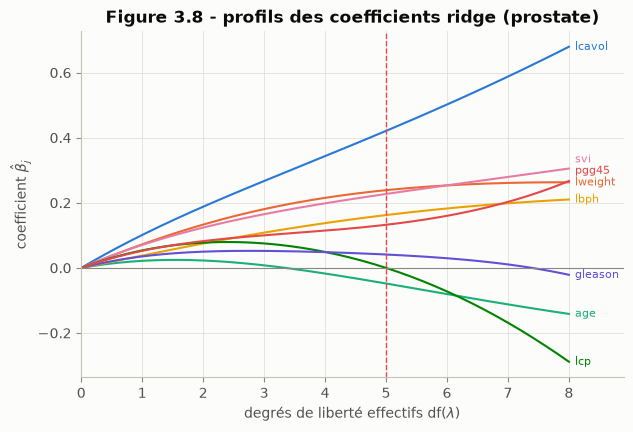

In [19]:
df_grid = np.linspace(0, p, 161)
b0_r, B_r = cr.ridge_path_df(Xtr, ytr, df_grid)
fig, ax = plt.subplots()
for j in range(p):
    ax.plot(df_grid, B_r[:, j], color=COLORS[j], linewidth=1.5)
label_ends(ax, p + 0.1, B_r[-1], names)
ax.axhline(0, color=GRAY, linewidth=0.8)
ax.axvline(5, color=COLORS[7], linestyle="--", linewidth=1)
ax.set_xlim(0, p + 0.9)
ax.set_title("Figure 3.8 - profils des coefficients ridge (prostate)")
ax.set_xlabel(r"degrés de liberté effectifs df($\lambda$)"); ax.set_ylabel(r"coefficient $\hat\beta_j$")
plt.show()

Les coefficients sont rétrécis **continûment** vers 0, mais aucun ne s'annule exactement
(sauf pour $\lambda = \infty$) : ridge ne fait pas de sélection. Certains coefficients
changent même de signe (`lcp`) : rétrécir l'ensemble n'est pas rétrécir chaque coordonnée.

### 4.5 Validation croisée (figure 3.7, panneau ridge)

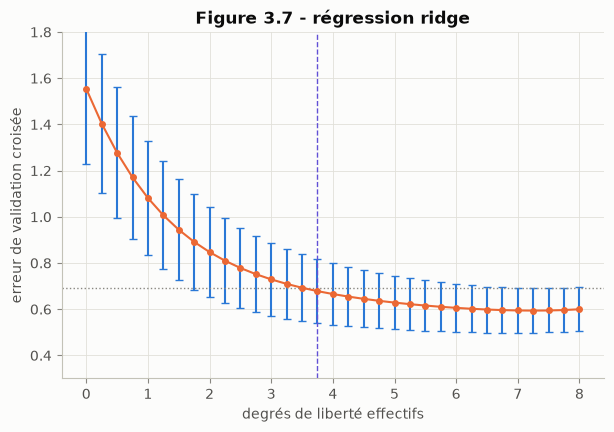

df retenu = 3.75 (lambda = 51.0) ; erreur de test = 0.513


In [20]:
df_cv = np.linspace(0, p, 33)
cv_r, se_r = cr.cv_error(lambda X, y: cr.ridge_path_df(X, y, df_cv), Xtr, ytr, folds)
fig, ax = plt.subplots()
i_r = plot_cv(ax, df_cv, cv_r, se_r, "Figure 3.7 - régression ridge", "degrés de liberté effectifs")
plt.show()
df_r = df_cv[i_r]
lam_r = cr.ridge_lambda_for_df(Xtr, df_r)
b0, b = cr.ridge_fit(Xtr, ytr, lam_r)
print("df retenu = %.2f (lambda = %.1f) ; erreur de test = %.3f" % (df_r, lam_r, test_error(b0, b)))

La courbe est très plate à partir de $\mathrm{df} \approx 3$ ; la règle un écart-type retient
ici un modèle un peu plus rétréci que celui du livre ($\mathrm{df} = 5$). Les deux choix
donnent des erreurs de test proches.

> **Interprétation bayésienne (exercice 3.6).** Si $y \sim \mathcal{N}(\mathbf{X}\beta, \sigma^2\mathbf{I})$
> et a priori $\beta \sim \mathcal{N}(0, \tau^2\mathbf{I})$, l'estimateur ridge avec
> $\lambda = \sigma^2/\tau^2$ est la moyenne (et le mode) de la loi a posteriori.

## 5. Le lasso

Le **lasso** remplace la pénalité quadratique par une pénalité en **valeur absolue**
(éq. (3.51)–(3.52)) :

$$
\hat\beta^{\mathrm{lasso}} = \underset{\beta}{\mathrm{argmin}}
\Bigl\{\frac12\sum_{i=1}^N\Bigl(y_i - \beta_0 - \sum_{j=1}^p x_{ij}\beta_j\Bigr)^2 + \lambda\sum_{j=1}^p|\beta_j|\Bigr\},
$$

ou, de façon équivalente, on minimise le RSS sous la contrainte $\sum_j|\beta_j| \le t$.
Comme pour ridge, on standardise les entrées et l'on ne pénalise pas $\beta_0$
($\hat\beta_0 = \bar y$ après centrage).

Différences essentielles avec ridge :
- le critère n'est plus dérivable en $\beta_j = 0$ : **pas de formule explicite** en
  général (c'est un problème d'optimisation convexe, résolu numériquement) ;
- pour $t$ assez petit, certains coefficients sont **exactement nuls** : le lasso fait une
  **sélection continue** de variables.

Si $t \ge t_0 = \sum_j|\hat\beta_j^{\mathrm{ls}}|$, la contrainte est inactive et l'on
retrouve les moindres carrés. On repère le chemin par le **facteur de rétrécissement**
$s = t/t_0 \in [0, 1]$.

### 5.1 Le cas d'une seule variable : seuillage doux

Pour comprendre d'où viennent les zéros, minimisons en $b \in \mathbb{R}$

$$
g(b) = \tfrac12 (z - b)^2 + \lambda|b|, \qquad \lambda > 0 .
$$

- Sur $b > 0$, $g'(b) = b - z + \lambda$ s'annule en $b = z - \lambda$, admissible si $z > \lambda$.
- Sur $b < 0$, $g'(b) = b - z - \lambda$ s'annule en $b = z + \lambda$, admissible si $z < -\lambda$.
- Si $|z| \le \lambda$, $g$ est décroissante sur $]-\infty, 0]$ et croissante sur
  $[0, +\infty[$ (les dérivées à gauche et à droite en 0 valent $-z - \lambda \le 0$ et
  $-z + \lambda \ge 0$) : le minimum est en $b = 0$.

On obtient l'opérateur de **seuillage doux** :

$$
\hat b = S(z, \lambda) = \mathrm{signe}(z)\,\bigl(|z| - \lambda\bigr)_+ .
$$

Dans le cas d'entrées **orthonormées**, chaque coefficient lasso vaut
$S(\hat\beta_j^{\mathrm{ls}}, \lambda)$, alors que ridge donne $\hat\beta_j/(1+\lambda)$ et
le meilleur sous-ensemble un **seuillage dur** (on garde les $M$ plus grands $|\hat\beta_j|$)
- tableau 3.4 du livre, établi dans l'exercice 3.16.

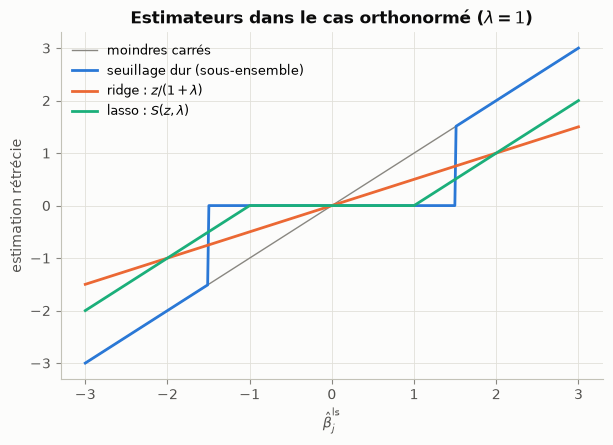

In [21]:
z = np.linspace(-3, 3, 400)
lam = 1.0
fig, ax = plt.subplots()
ax.plot(z, z, color=GRAY, linewidth=1, label="moindres carrés")
ax.plot(z, z * (np.abs(z) > 1.5), color=COLORS[0], label="seuillage dur (sous-ensemble)")
ax.plot(z, z / (1 + lam), color=COLORS[1], label=r"ridge : $z/(1+\lambda)$")
ax.plot(z, cr.soft_threshold(z, lam), color=COLORS[2], label=r"lasso : $S(z, \lambda)$")
ax.set_title(r"Estimateurs dans le cas orthonormé ($\lambda = 1$)")
ax.set_xlabel(r"$\hat\beta_j^{\mathrm{ls}}$"); ax.set_ylabel("estimation rétrécie")
ax.legend()
plt.show()

### 5.2 Algorithme : la descente de coordonnées

Le calcul du cas d'une variable suggère un algorithme général (§3.8.6, éq. (3.84)) : on
optimise **une coordonnée à la fois**, les autres étant fixées, et l'on cycle jusqu'à
convergence. Pour la coordonnée $j$, en notant
$\mathbf{r}^{(j)} = \mathbf{y} - \sum_{k\ne j}\mathbf{x}_k\beta_k$ le **résidu partiel**,
le critère en $\beta_j$ est
$\frac12\lVert\mathbf{r}^{(j)} - \mathbf{x}_j\beta_j\rVert^2 + \lambda|\beta_j| + \text{cte}$,
minimisé par

$$
\beta_j \leftarrow \frac{S\bigl(\langle\mathbf{x}_j, \mathbf{r}^{(j)}\rangle,\ \lambda\bigr)}{\lVert\mathbf{x}_j\rVert^2}.
$$

(On développe le carré : $\frac12\lVert\mathbf{x}_j\rVert^2\beta_j^2 - \langle\mathbf{x}_j, \mathbf{r}^{(j)}\rangle\beta_j + \lambda|\beta_j|$,
puis on divise par $\lVert\mathbf{x}_j\rVert^2$ pour se ramener au cas précédent.)

Le critère étant convexe et la pénalité séparable (somme de fonctions d'une seule
coordonnée), ces mises à jour convergent vers le minimum. C'est ce que fait
`cr.lasso_cd` ; comparons-le à `sklearn.linear_model.Lasso`, qui minimise
$\frac{1}{2N}\mathrm{RSS} + \alpha\lVert\beta\rVert_1$, soit $\alpha = \lambda/N$.

In [ ]:
for lam in (2.0, 10.0):
    b0, b = cr.lasso_cd(Xtr, ytr, lam)
    sk = Lasso(alpha=lam / N, tol=1e-12, max_iter=100000).fit(Xtr, ytr)
    print("lambda = %4.1f : coefficients = %s" % (lam, b.round(3)))
    print("               écart max avec sklearn = %.1e" % np.abs(b - sk.coef_).max())

Le lasso annule **exactement** plusieurs coefficients. Au-delà de
$\lambda_{\max} = \max_j|\langle\mathbf{x}_j, \mathbf{y} - \bar y\rangle|$, tous sont nuls
(dérivée à droite et à gauche en $\beta = 0$ de signes opposés pour chaque coordonnée).